# Altair OPS — held-out **guide-level** morphology → expression predictor
Builds on Tim Treis's [`cytodata-hackathon-prep-ops`](https://github.com/timtreis/cytodata-hackathon-prep-ops) starter: it ships one mantispy-processed **phase profile per guide** (`phase_guide.h5ad`, 4,211 guides × 3,317 features) and shows how to join Biohub's **CROP-seq** embedding by guide. Here we take that join and put a **rigorous held-out cross-modal predictor** on it — the question "can label-free morphology predict the perturbation transcriptome, and where does it fail", at **single-guide** resolution.

**Design:** match phase guides to CROP-seq `emb_guide` by 20-nt guide sequence; drop NTCs; 5-fold **out-of-fold on held-out guides**, per-fold `StandardScaler` (no leakage), multi-output `RidgeCV`. Metrics: held-out R², cross-modal **retrieval** (rank the true guide among all guides), **cross-validated CCA**. Then we aggregate guides→genes to show where the signal concentrates.

**Why guide-level matters:** the CROP-seq cells are *not* the imaged cells, so morphology and RNA only line up at the perturbation level (guide, then gene) — never per cell. This notebook works at the finest valid resolution and compares it to the gene level.

In [1]:
import os, zipfile, warnings
from pathlib import Path
import anndata as ad, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cross_decomposition import CCA
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi":110,"font.size":10,"axes.spines.top":False,"axes.spines.right":False})
rng=np.random.default_rng(0); DATA=Path("data"); DATA.mkdir(exist_ok=True)
FIG=Path("figures/guide_level"); FIG.mkdir(parents=True, exist_ok=True)

# phase guide profiles (Tim's prep-ops CDN); CROP-seq from Biohub's Zenodo (altair_v2)
if not (DATA/"phase_guide.h5ad").exists():
    os.system('curl -s -o data/phase_guide.h5ad https://exampledata.scverse.org/sbi2-cytodata/ops/phase_guide.h5ad')
if not (DATA/"cropseq_svaeplus.h5ad").exists():
    import pooch
    z=pooch.retrieve("https://zenodo.org/api/records/21970895/files/altair_v2.zip/content",
                     known_hash=None, fname="altair_v2.zip", path=DATA, progressbar=False)
    with zipfile.ZipFile(z) as zz: zz.extract("figures/figure_5/cropseq_svaeplus.h5ad", DATA)
    os.replace(DATA/"figures/figure_5/cropseq_svaeplus.h5ad", DATA/"cropseq_svaeplus.h5ad")
MARKERS4I=["gh2ax","p21","p53","prb","rb","rsp6"]
if not all((DATA/f"{m}_guide.h5ad").exists() for m in MARKERS4I):
    os.system('curl -s -o data/markers_guide.zip https://exampledata.scverse.org/sbi2-cytodata/ops/markers_guide.zip')
    with zipfile.ZipFile(DATA/"markers_guide.zip") as zz:
        for m in MARKERS4I: zz.extract(f"{m}_guide.h5ad", DATA)
print("data ready")

data ready


## 1. Match phase guides to CROP-seq (by 20-nt guide sequence)

In [2]:
ph=ad.read_h5ad(DATA/"phase_guide.h5ad")
ph=ph[:, ph.var["selected"].values].copy()          # mantispy feature selection
ph.X=np.clip(np.nan_to_num(ph.X),-50,50)             # Tim's recommended clip
rna=ad.read_h5ad(DATA/"cropseq_svaeplus.h5ad")
emb={s:rna.obsm["emb_guide"][i] for i,s in enumerate(rna.obs["sgRNA"].astype(str))}
g=ph.obs["guide"].astype(str).values; tgt=ph.obs["target_gene"].astype(str).values
keep=np.array([(gg in emb) and (tt!="NTC") for gg,tt in zip(g,tgt)])
P=ph.X[keep]; R=np.vstack([emb[gg] for gg in g[keep]]); genes=tgt[keep]
print(f"matched KO guides: {keep.sum()} | phase {P.shape} -> RNA {R.shape} | genes: {len(set(genes))} ({keep.sum()/len(set(genes)):.1f}/gene)")

matched KO guides: 4000 | phase (4000, 337) -> RNA (4000, 50) | genes: 1000 (4.0/gene)


## 2. Held-out cross-modal prediction (out-of-fold, per-fold scaling)
For every guide, predict its transcriptome embedding from its morphology (and the reverse), evaluated on held-out guides. **Retrieval** asks: query the gallery of all guides with a guide's *predicted* embedding — how often is its true match in the top-k (chance = k/N).

[phase→RNA] R2 unif=0.337 var-wt=0.414 | top1=0.019 top5=0.087 top10=0.132 med_rank=240/4000


[RNA→phase] R2 unif=0.605 var-wt=0.762 | top1=0.015 top5=0.056 top10=0.086 med_rank=669/4000


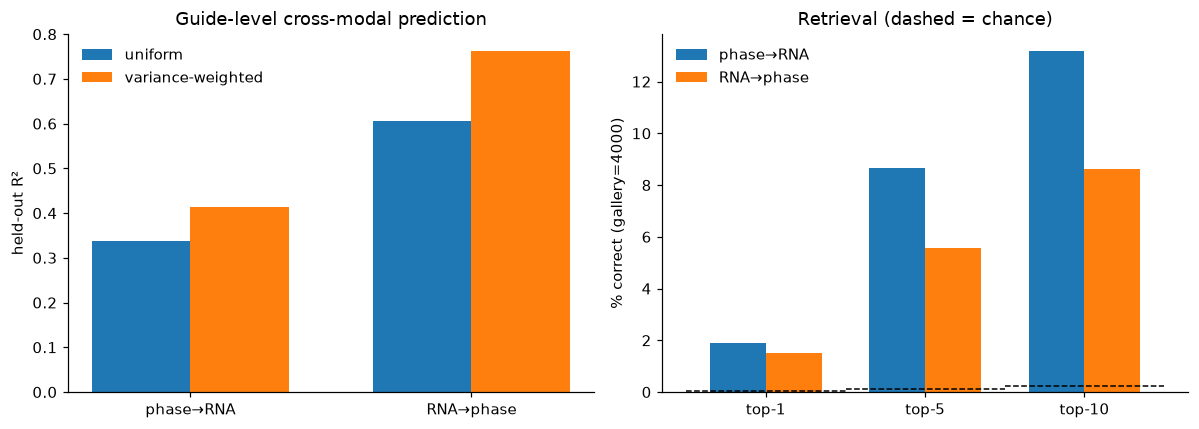

In [3]:
alphas=np.logspace(-1,4,12)
def oof(X,Y):
    O=np.zeros_like(Y)
    for tr,te in KFold(5,shuffle=True,random_state=0).split(X):
        xs,ys=StandardScaler().fit(X[tr]),StandardScaler().fit(Y[tr])
        m=RidgeCV(alphas=alphas).fit(xs.transform(X[tr]),ys.transform(Y[tr]))
        O[te]=ys.inverse_transform(m.predict(xs.transform(X[te])))
    return O
def retr(pred,act):
    S=cosine_similarity(pred,act); order=np.argsort(-S,1)
    rk=np.array([np.where(order[i]==i)[0][0] for i in range(len(pred))])
    return dict(top1=np.mean(rk==0),top5=np.mean(rk<5),top10=np.mean(rk<10),med=float(np.median(rk)+1))
res={}
for name,X,Y in [("phase→RNA",P,R),("RNA→phase",R,P)]:
    O=oof(X,Y); res[name]=dict(r2u=r2_score(Y,O,multioutput="uniform_average"),
        r2v=r2_score(Y,O,multioutput="variance_weighted"),**retr(O,Y))
    r=res[name]; print(f"[{name}] R2 unif={r['r2u']:.3f} var-wt={r['r2v']:.3f} | top1={r['top1']:.3f} top5={r['top5']:.3f} top10={r['top10']:.3f} med_rank={r['med']:.0f}/{keep.sum()}")

n=keep.sum(); fig,ax=plt.subplots(1,2,figsize=(11,4)); d=list(res); x=np.arange(len(d)); w=0.35
ax[0].bar(x-w/2,[res[k]['r2u'] for k in d],w,label="uniform"); ax[0].bar(x+w/2,[res[k]['r2v'] for k in d],w,label="variance-weighted")
ax[0].set_xticks(x); ax[0].set_xticklabels(d); ax[0].set_ylabel("held-out R²"); ax[0].set_title("Guide-level cross-modal prediction"); ax[0].legend(frameon=False); ax[0].set_ylim(0,0.8)
ks=["top1","top5","top10"]; xk=np.arange(3)
for i,k in enumerate(d): ax[1].bar(xk+(i-0.5)*w,[res[k][z]*100 for z in ks],w,label=k)
for j,kk in enumerate([1,5,10]): ax[1].plot([xk[j]-.5,xk[j]+.5],[kk/n*100]*2,"k--",lw=1)
ax[1].set_xticks(xk); ax[1].set_xticklabels(["top-1","top-5","top-10"]); ax[1].set_ylabel(f"% correct (gallery={n})"); ax[1].set_title("Retrieval (dashed = chance)"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG/"guide_r2_retrieval.png",bbox_inches="tight",dpi=150); plt.show()

## 3. Cross-validated CCA — shared axes survive held-out evaluation

held-out canonical corr: [0.953 0.873 0.888 0.809 0.781 0.667 0.573 0.647 0.565 0.513]


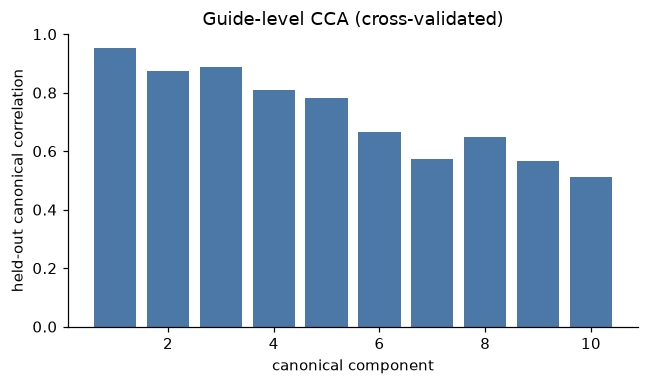

In [4]:
nc=10; tc=np.zeros((5,nc))
for f,(tr,te) in enumerate(KFold(5,shuffle=True,random_state=0).split(P)):
    xs,ys=StandardScaler().fit(P[tr]),StandardScaler().fit(R[tr])
    c=CCA(n_components=nc,max_iter=2000).fit(xs.transform(P[tr]),ys.transform(R[tr]))
    a,b=c.transform(xs.transform(P[te]),ys.transform(R[te]))
    tc[f]=[np.corrcoef(a[:,i],b[:,i])[0,1] for i in range(nc)]
hc=tc.mean(0); print("held-out canonical corr:",np.round(hc,3))
fig,ax=plt.subplots(figsize=(6,3.6)); ax.bar(range(1,nc+1),hc,color="#4C78A8"); ax.set_ylim(0,1)
ax.set_xlabel("canonical component"); ax.set_ylabel("held-out canonical correlation"); ax.set_title("Guide-level CCA (cross-validated)")
plt.tight_layout(); plt.savefig(FIG/"guide_cca.png",bbox_inches="tight",dpi=150); plt.show()

## 4. Guide level vs gene level — where does the signal concentrate?
Single guides are noisier than the gene (4 guides/gene). Aggregating guides→genes should sharpen the cross-modal link. We average the matched phase and RNA embeddings per gene and re-run the predictor.

[gene-level phase→RNA] R2 unif=0.347 | top10=0.302 med_rank=44/1000


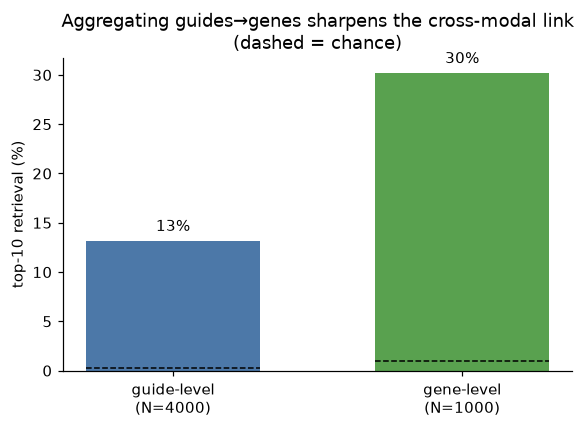

In [5]:
dfg=pd.DataFrame(P); dfg["g"]=genes; Pg=dfg.groupby("g").mean().values
dfr=pd.DataFrame(R); dfr["g"]=genes; Rg=dfr.groupby("g").mean().values
Og=oof(Pg,Rg); mg=retr(Og,Rg); ng=Pg.shape[0]
print(f"[gene-level phase→RNA] R2 unif={r2_score(Rg,Og,multioutput='uniform_average'):.3f} | top10={mg['top10']:.3f} med_rank={mg['med']:.0f}/{ng}")
lab=["guide-level\n(N=%d)"%n,"gene-level\n(N=%d)"%ng]
fig,ax=plt.subplots(figsize=(5.4,4))
ax.bar([0,1],[res['phase→RNA']['top10']*100, mg['top10']*100],color=["#4C78A8","#59A14F"],width=.6)
for i,(v,ch) in enumerate([(res['phase→RNA']['top10'],10/n),(mg['top10'],10/ng)]):
    ax.text(i,v*100+1,f"{v*100:.0f}%",ha="center"); ax.plot([i-.3,i+.3],[ch*100]*2,"k--",lw=1)
ax.set_xticks([0,1]); ax.set_xticklabels(lab); ax.set_ylabel("top-10 retrieval (%)"); ax.set_title("Aggregating guides→genes sharpens the cross-modal link\n(dashed = chance)")
plt.tight_layout(); plt.savefig(FIG/"guide_vs_gene.png",bbox_inches="tight",dpi=150); plt.show()

## 5. What the fixed 4i panel adds (Brian's OPS0077 idea)
OPS0077 is the 4i *fixed* screen — the same cells carry γH2AX, p21, p53, pRb, Rb and RPS6 (DNA-damage / cell-cycle / translation stress). Does this panel add cross-modal signal over label-free phase for predicting the transcriptome? We join each marker's guide profile and reduce **each modality to 40 PCs** so the comparison is size-balanced (otherwise the 1,655 marker features swamp the 337 phase features).

[phase    ->RNA]  R2=0.328  top10=0.112  (n=3997)


[4i       ->RNA]  R2=0.102  top10=0.012  (n=3997)


[phase+4i ->RNA]  R2=0.327  top10=0.115  (n=3997)


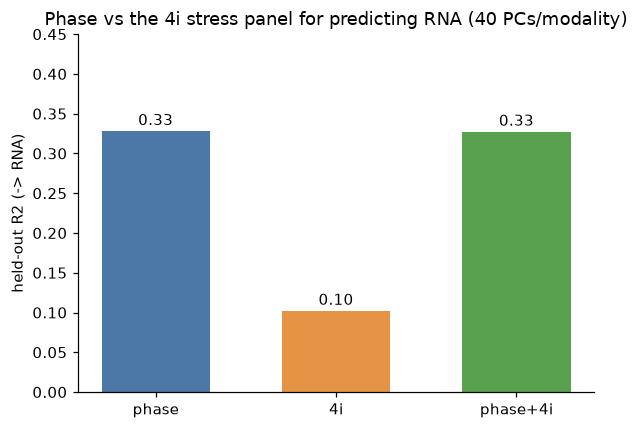

In [6]:
markers4i=["gh2ax","p21","p53","prb","rb","rsp6"]
def load_sel(fn):
    a=ad.read_h5ad(DATA/fn); a=a[:,a.var["selected"].values].copy()
    a.X=np.clip(np.nan_to_num(a.X),-50,50); return a
mk={m:load_sel(f"{m}_guide.h5ad") for m in markers4i}
common=set(ph.obs["guide"].astype(str))
for m in markers4i: common&=set(mk[m].obs["guide"].astype(str))
pgx=ph.obs.set_index(ph.obs["guide"].astype(str))
gid=sorted(x for x in common if x in emb and pgx.loc[x,"target_gene"]!="NTC")
pix={x:i for i,x in enumerate(ph.obs["guide"].astype(str))}
mixm={m:{x:i for i,x in enumerate(mk[m].obs["guide"].astype(str))} for m in markers4i}
PHc=np.vstack([ph.X[pix[x]] for x in gid])
MKc=np.hstack([np.vstack([mk[m].X[mixm[m][x]] for x in gid]) for m in markers4i])
Rc=np.vstack([emb[x] for x in gid]); nc=len(gid)
from sklearn.decomposition import PCA
def oof_pca(blocks,Y,Kp=40):
    O=np.zeros_like(Y)
    for tr,te in KFold(5,shuffle=True,random_state=0).split(Y):
        Xt=[];Xe=[]
        for B in blocks:
            p=PCA(n_components=min(Kp,B.shape[1]),random_state=0).fit(B[tr])
            Xt.append(p.transform(B[tr])); Xe.append(p.transform(B[te]))
        ys=StandardScaler().fit(Y[tr])
        O[te]=ys.inverse_transform(RidgeCV(alphas=alphas).fit(np.hstack(Xt),ys.transform(Y[tr])).predict(np.hstack(Xe)))
    return O
r4={}
for nm,bl in [("phase",[PHc]),("4i",[MKc]),("phase+4i",[PHc,MKc])]:
    O=oof_pca(bl,Rc); r4[nm]=(r2_score(Rc,O,multioutput="uniform_average"), retr(O,Rc)["top10"])
    print(f"[{nm:9s}->RNA]  R2={r4[nm][0]:.3f}  top10={r4[nm][1]:.3f}  (n={nc})")
fig,ax=plt.subplots(figsize=(5.6,4)); nmz=list(r4); xx=np.arange(len(nmz))
ax.bar(xx,[r4[k][0] for k in nmz],color=["#4C78A8","#E49444","#59A14F"],width=.6)
for i,k in enumerate(nmz): ax.text(i,r4[k][0]+.008,f"{r4[k][0]:.2f}",ha="center")
ax.set_xticks(xx); ax.set_xticklabels(nmz); ax.set_ylim(0,0.45)
ax.set_ylabel("held-out R2 (-> RNA)"); ax.set_title("Phase vs the 4i stress panel for predicting RNA (40 PCs/modality)")
plt.tight_layout(); plt.savefig(FIG/"phase_vs_4i.png",bbox_inches="tight",dpi=150); plt.show()

## 6. Representation ranking: Cell-DINO vs phase vs 4i (gene level)
The atlas also ships a **learned Cell-DINO** embedding (`atlas/aggregated_data.h5ad`, gene-level, 66 sparse-PCs of the live-cell DINO model). Here we rank every imaging representation for predicting the CROP-seq transcriptome at the gene level (each block reduced to a balanced 40 PCs, so size does not confound the comparison).

[Cell-DINO             ->RNA] R2=0.467 top10=0.404 (n=1000)
[phase                 ->RNA] R2=0.343 top10=0.279 (n=1000)


[4i                    ->RNA] R2=0.134 top10=0.071 (n=1000)
[Cell-DINO +phase      ->RNA] R2=0.467 top10=0.404 (n=1000)


[Cell-DINO +phase+4i   ->RNA] R2=0.468 top10=0.400 (n=1000)


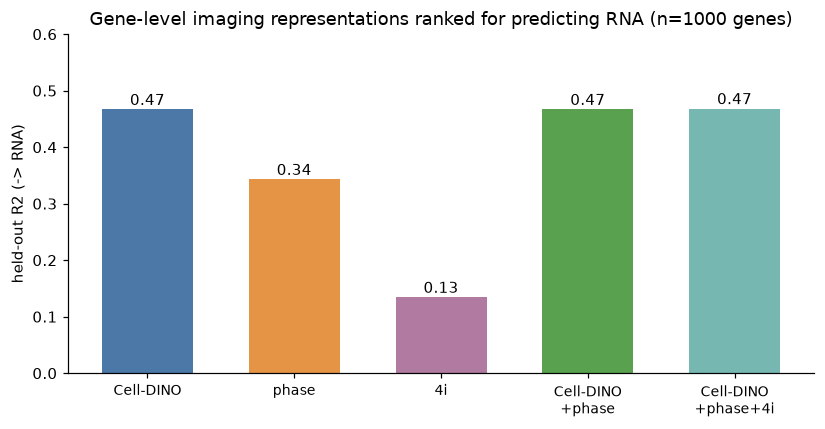

In [7]:
import os
from sklearn.decomposition import PCA
if not os.path.exists("data/aggregated_data.h5ad"):
    os.system('curl -s -o data/aggregated_data.h5ad "https://ops-explorer-public.s3.us-west-2.amazonaws.com/leonetti_ops/ops_data_portal_submission/v2.0.20260724/atlas/aggregated_data.h5ad"')
def to_gene(Xarr, genes):
    df=pd.DataFrame(Xarr,index=pd.Index(genes)); df=df[~df.index.isin(["NTC","control","nontargeting"])]; return df.groupby(level=0).mean()
phg=to_gene(ph.X, ph.obs["target_gene"].astype(str).values)
m4=[to_gene(mk[m].X, mk[m].obs["target_gene"].astype(str).values) for m in markers4i]
rg=pd.DataFrame(rna.obsm["emb_guide"],index=pd.Index(rna.obs["Perturbation"].astype(str))); RNAg=rg[rg.index!="control"].groupby(level=0).mean()
dino=ad.read_h5ad("data/aggregated_data.h5ad"); gc=[c for c in ("geneKO_name","perturbation_id") if c in dino.obs][0]
DINOg=pd.DataFrame(np.asarray(dino.X),index=pd.Index(dino.obs[gc].astype(str)))
shb=sorted(set(phg.index)&set(RNAg.index)&set(DINOg.index)&set.intersection(*[set(x.index) for x in m4]))
Yg=RNAg.loc[shb].values
M4=lambda: np.hstack([x.loc[shb].values for x in m4])
reps={"Cell-DINO":[DINOg.loc[shb].values],"phase":[phg.loc[shb].values],"4i":[M4()],
      "Cell-DINO\n+phase":[DINOg.loc[shb].values,phg.loc[shb].values],
      "Cell-DINO\n+phase+4i":[DINOg.loc[shb].values,phg.loc[shb].values,M4()]}
def oofb(bl,Y,K=40):
    O=np.zeros_like(Y)
    for tr,te in KFold(5,shuffle=True,random_state=0).split(Y):
        Xt=[];Xe=[]
        for B in bl:
            p=PCA(n_components=min(K,B.shape[1]),random_state=0).fit(B[tr]); Xt.append(p.transform(B[tr])); Xe.append(p.transform(B[te]))
        ys=StandardScaler().fit(Y[tr]); O[te]=ys.inverse_transform(RidgeCV(alphas=alphas).fit(np.hstack(Xt),ys.transform(Y[tr])).predict(np.hstack(Xe)))
    return O
rk={}
for nm,bl in reps.items():
    O=oofb(bl,Yg); S=cosine_similarity(O,Yg); rr=np.array([np.where(np.argsort(-S[i])==i)[0][0] for i in range(len(O))])
    rk[nm]=(r2_score(Yg,O,multioutput="uniform_average"), float(np.mean(rr<10)))
    print(f"[{nm.replace(chr(10),' '):22s}->RNA] R2={rk[nm][0]:.3f} top10={rk[nm][1]:.3f} (n={len(shb)})")
fig,ax=plt.subplots(figsize=(7.6,4)); nmz=list(rk); xx=np.arange(len(nmz))
ax.bar(xx,[rk[k][0] for k in nmz],color=["#4C78A8","#E49444","#B07AA1","#59A14F","#76B7B2"],width=.62)
for i,k in enumerate(nmz): ax.text(i,rk[k][0]+.008,f"{rk[k][0]:.2f}",ha="center")
ax.set_xticks(xx); ax.set_xticklabels(nmz,fontsize=9); ax.set_ylabel("held-out R2 (-> RNA)"); ax.set_ylim(0,0.6)
ax.set_title(f"Gene-level imaging representations ranked for predicting RNA (n={len(shb)} genes)")
plt.tight_layout(); plt.savefig(FIG/"representation_ranking.png",bbox_inches="tight",dpi=150); plt.show()

## 7. Takeaways
- **Representation ranking (gene level): Cell-DINO > phase > 4i** (held-out R² approx 0.47 vs 0.34 vs 0.13), and Cell-DINO already subsumes phase and 4i (combinations do not improve). The learned embedding is the one to use.
- Morphology↔expression is predictable at single-guide resolution — phase→RNA R²≈0.34, RNA→phase R²≈0.61; cross-validated CCA keeps ~5 shared axes at r≈0.8–0.95.
- Aggregating guides→genes sharpens the link — the cross-modal signal concentrates at the gene level (single guides are noisy), echoing the known result that single-cell multimodal MoA is hard.
- **Phase ≫ the 4i stress panel for predicting the transcriptome** (R²≈0.33 vs ≈0.10), and **phase+4i ≈ phase** — this fixed γH2AX / cell-cycle / translation panel is largely redundant with label-free phase for cross-modal prediction. (Panel-specific: a broader marker set could add more.)
- Where one modality can't predict another marks modality-specific biology — the argument for keeping label-free imaging alongside transcriptomics.

**Caveats:** CROP-seq cells ≠ imaged cells (cross-modal only at perturbation level); mantispy-selected OrganelleProfiler features, not a learned/Cell-DINO embedding; linear predictors are a floor; the 4i result is specific to this stress-marker panel.